In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 2e-4
VAL_SIZE = 0.15
PATIENCE = 5
USE_PRETRAINED = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


In [3]:
DATA_ROOT = Path("/kaggle/input/brain-tumor-mri-dataset")

if (DATA_ROOT / "Training").exists():
    train_dir = DATA_ROOT / "Training"
    test_dir = DATA_ROOT / "Testing"

else:
    candidates = [
        p for p in Path("/kaggle/input").rglob("Training")
        if p.is_dir() and (p.parent / "Testing").is_dir()
    ]

    if not candidates:
        raise FileNotFoundError(
            "Dataset not found. Attach the Brain Tumor MRI Dataset."
        )

    train_dir = candidates[0]
    test_dir = train_dir.parent / "Testing"

print("Training:", train_dir)
print("Testing:", test_dir)

print("\nTraining classes:")
print(sorted(os.listdir(train_dir)))

print("\nTesting classes:")
print(sorted(os.listdir(test_dir)))

Training: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Testing: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing

Training classes:
['glioma', 'meningioma', 'notumor', 'pituitary']

Testing classes:
['glioma', 'meningioma', 'notumor', 'pituitary']


In [4]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
base_dataset = datasets.ImageFolder(train_dir)

class_names = base_dataset.classes
num_classes = len(class_names)

labels = np.array(base_dataset.targets)
indices = np.arange(len(base_dataset))

train_indices, val_indices = train_test_split(
    indices,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=labels
)

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    train_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

print("Classes:", class_names)
print("Number of classes:", num_classes)

print("\nDataset sizes:")
print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Testing:", len(test_dataset))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4

Dataset sizes:
Training: 4760
Validation: 840
Testing: 1600


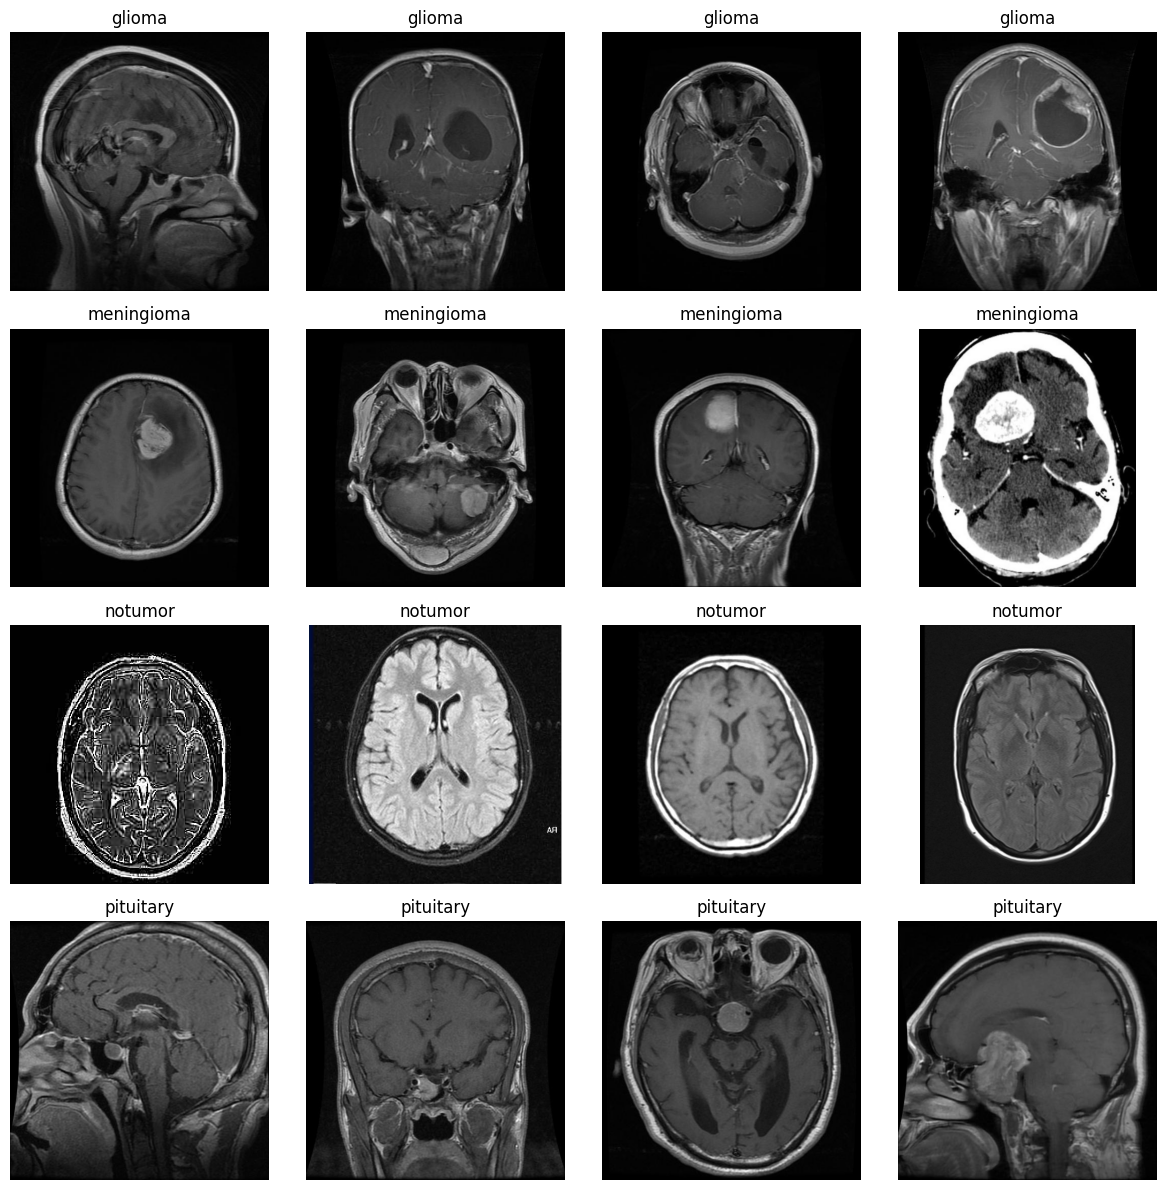

In [6]:
class_indices = {
    cls: np.where(labels == idx)[0]
    for idx, cls in enumerate(class_names)
}

fig, axes = plt.subplots(
    num_classes, 4,
    figsize=(12, 3 * num_classes)
)

for row, cls in enumerate(class_names):
    samples = np.random.choice(
        class_indices[cls],
        size=4,
        replace=False
    )

    for col, idx in enumerate(samples):
        image, label = base_dataset[idx]

        axes[row, col].imshow(image)
        axes[row, col].set_title(class_names[label])
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [7]:
NUM_WORKERS = 2

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 149
Validation batches: 27
Testing batches: 50


In [8]:
try:
    weights = (
        models.ResNet18_Weights.DEFAULT
        if USE_PRETRAINED else None
    )

    model = models.resnet18(weights=weights)

except Exception as e:
    print("Pretrained weights unavailable:", e)
    print("Using ResNet-18 with random initialization.")

    model = models.resnet18(weights=None)

model.fc = nn.Sequential(
    nn.Dropout(0.35),
    nn.Linear(model.fc.in_features, num_classes)
)

model = model.to(device)

print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 157MB/s] 


Sequential(
  (0): Dropout(p=0.35, inplace=False)
  (1): Linear(in_features=512, out_features=4, bias=True)
)


In [9]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.3,
    patience=2
)

amp_enabled = device.type == "cuda"

scaler = torch.cuda.amp.GradScaler(
    enabled=amp_enabled
)

OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = OUTPUT_DIR / "best_brain_tumor_resnet18.pth"

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

/tmp/ipykernel_50/50398311.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(


In [10]:
def run_epoch(loader, training=False):

    model.train(training)

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=amp_enabled):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    train_loss, train_acc = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_epoch(
        val_loader,
        training=False
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f} "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break


model.load_state_dict(
    torch.load(BEST_MODEL_PATH, map_location=device)
)

print("\nBest validation loss:", best_val_loss)
print("Best model saved at:", BEST_MODEL_PATH)

/tmp/ipykernel_50/4286117143.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=amp_enabled):


Epoch [1/15] Train Loss: 0.4316 Train Acc: 0.9088 Val Loss: 0.3063 Val Acc: 0.9595 LR: 0.000200
Epoch [2/15] Train Loss: 0.3069 Train Acc: 0.9643 Val Loss: 0.2710 Val Acc: 0.9810 LR: 0.000200
Epoch [3/15] Train Loss: 0.2694 Train Acc: 0.9811 Val Loss: 0.2593 Val Acc: 0.9810 LR: 0.000200
Epoch [4/15] Train Loss: 0.2442 Train Acc: 0.9914 Val Loss: 0.2545 Val Acc: 0.9821 LR: 0.000200
Epoch [5/15] Train Loss: 0.2342 Train Acc: 0.9941 Val Loss: 0.2410 Val Acc: 0.9893 LR: 0.000200
Epoch [6/15] Train Loss: 0.2496 Train Acc: 0.9876 Val Loss: 0.2480 Val Acc: 0.9905 LR: 0.000200
Epoch [7/15] Train Loss: 0.2315 Train Acc: 0.9941 Val Loss: 0.2353 Val Acc: 0.9905 LR: 0.000200
Epoch [8/15] Train Loss: 0.2259 Train Acc: 0.9956 Val Loss: 0.2671 Val Acc: 0.9774 LR: 0.000200
Epoch [9/15] Train Loss: 0.2267 Train Acc: 0.9950 Val Loss: 0.2397 Val Acc: 0.9810 LR: 0.000200
Epoch [10/15] Train Loss: 0.2255 Train Acc: 0.9960 Val Loss: 0.2213 Val Acc: 0.9917 LR: 0.000200
Epoch [11/15] Train Loss: 0.2238 Train 

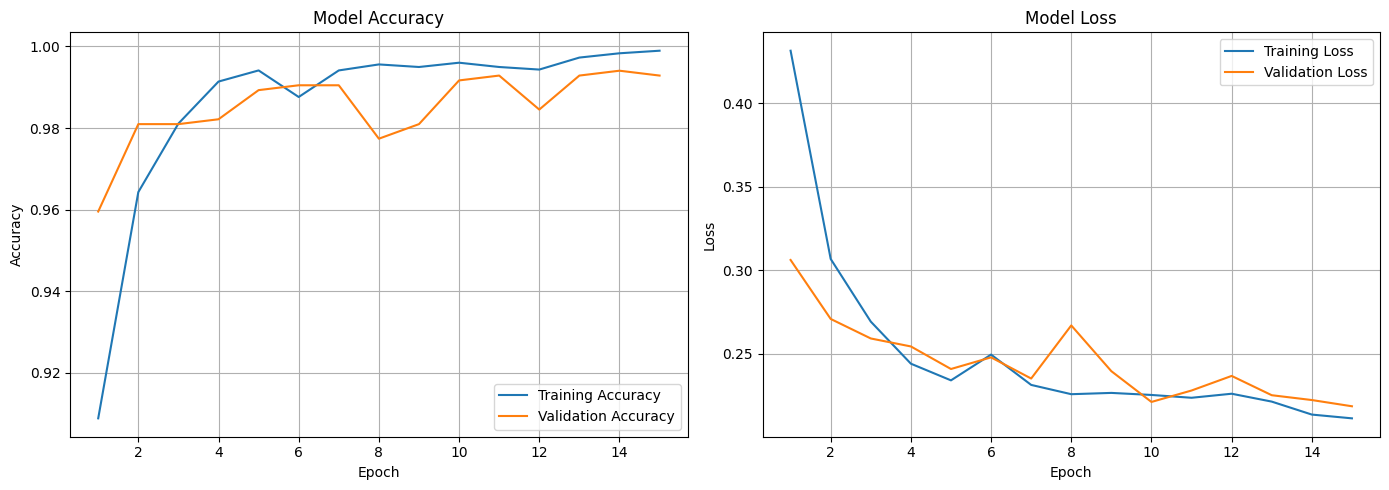

In [11]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs_range,
    history["train_acc"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)

axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [12]:
model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())


test_accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Test Accuracy:", round(test_accuracy, 4))
print("Macro Precision:", round(precision, 4))
print("Macro Recall:", round(recall, 4))
print("Macro F1 Score:", round(f1, 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

Test Accuracy: 0.9513
Macro Precision: 0.9546
Macro Recall: 0.9513
Macro F1 Score: 0.9501

Classification Report:

              precision    recall  f1-score   support

      glioma     0.9940    0.8225    0.9001       400
  meningioma     0.9039    0.9875    0.9438       400
     notumor     0.9281    1.0000    0.9627       400
   pituitary     0.9925    0.9950    0.9938       400

    accuracy                         0.9513      1600
   macro avg     0.9546    0.9513    0.9501      1600
weighted avg     0.9546    0.9513    0.9501      1600



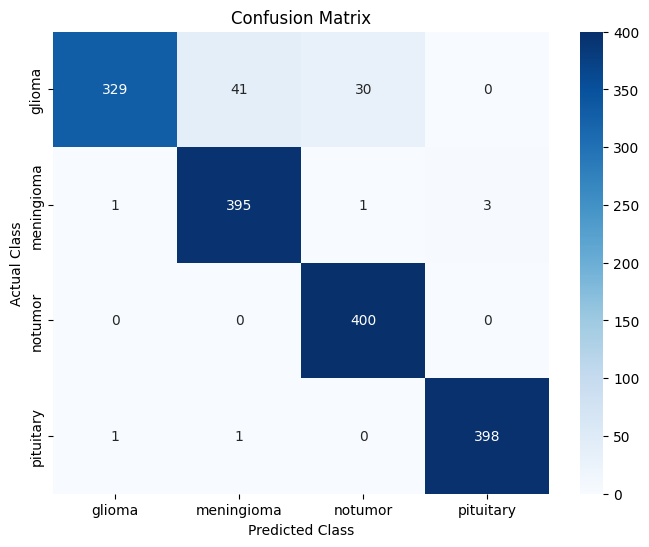

In [13]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()

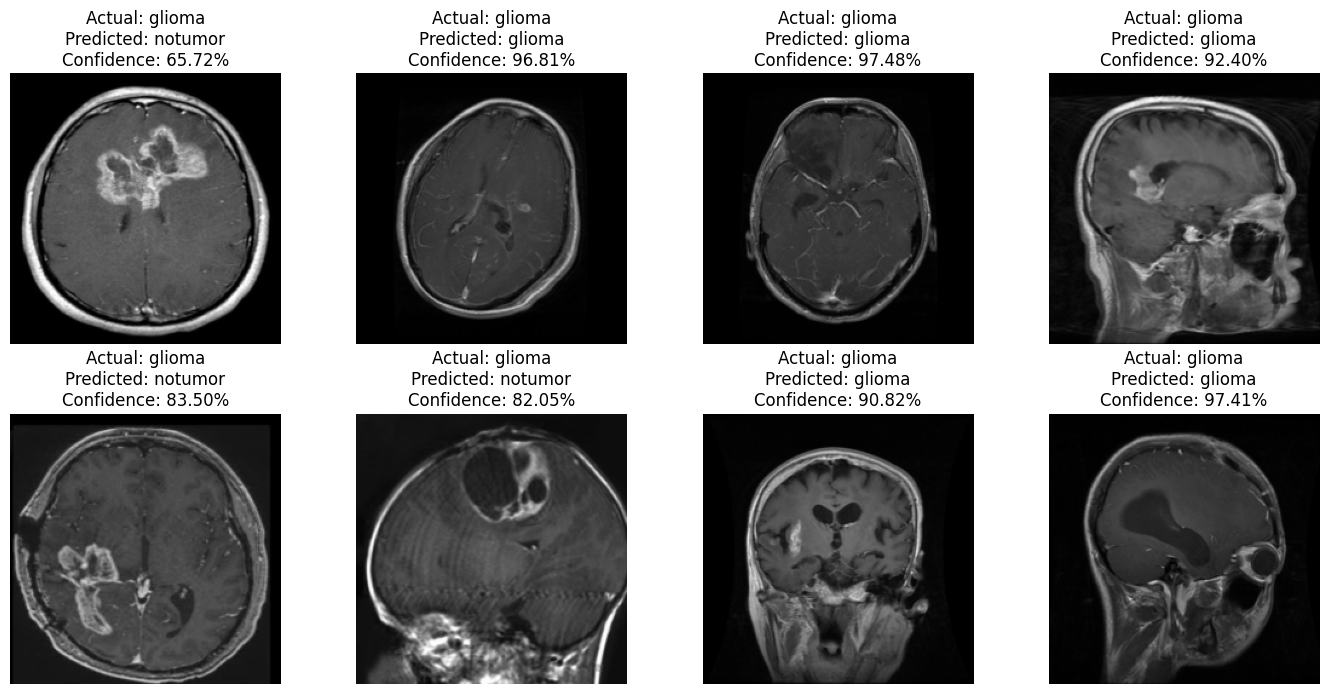

In [14]:
images, labels = next(iter(test_loader))

images_device = images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images_device)
    probabilities = torch.softmax(outputs, dim=1)
    predictions = probabilities.argmax(dim=1)

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(1, 3, 1, 1)

images = (images * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    image = images[i].permute(1, 2, 0).numpy()

    true_label = class_names[labels[i].item()]
    predicted_label = class_names[predictions[i].item()]
    confidence = probabilities[i].max().item() * 100

    ax.imshow(image)

    ax.set_title(
        f"Actual: {true_label}\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence:.2f}%"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()